# Transfer Learning

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os
GDRIVE = "/content/drive/MyDrive/brain-tumor-mri"
os.makedirs("/content/project/data", exist_ok=True)
os.makedirs("/content/project/notebooks", exist_ok=True)

!cp -r "{GDRIVE}/src" /content/project/
!unzip -q -o "{GDRIVE}/Tumour.zip" -d /content/project/data
%cd /content/project/notebooks
!ls /content/project/data/Tumour

ModuleNotFoundError: No module named 'google.colab'

1: Imports

In [3]:
import sys
sys.path.append("..")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

from src.config import *
from src.data_utils import get_datasets, get_class_weights
from src.models import build_transfer_model, unfreeze_top_layers

keras.utils.set_random_seed(SEED)
print("TF:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF: 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


2: Data and class weights

In [4]:
train_ds, val_ds, test_ds = get_datasets()
class_weights = get_class_weights()

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.


3: Training function (two phases) and plotting

In [6]:
results = {}

def plot_history(name, h1, h2):
    acc  = h1.history["accuracy"] + h2.history["accuracy"]
    vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
    loss  = h1.history["loss"] + h2.history["loss"]
    vloss = h1.history["val_loss"] + h2.history["val_loss"]
    boundary = len(h1.history["loss"]) - 0.5

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for a, tr, va, title in [(ax[0], acc, vacc, "Accuracy"), (ax[1], loss, vloss, "Loss")]:
        a.plot(tr, label="Train"); a.plot(va, label="Validation")
        a.axvline(boundary, color="gray", linestyle="--", label="Start fine-tuning")
        a.set_title(f"{name}: {title}"); a.set_xlabel("Epoch"); a.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"04_{name}_history.png", dpi=150)
    plt.show()


def train_transfer(name, epochs_head=15, epochs_ft=15, unfreeze=40):
    keras.utils.set_random_seed(SEED)
    model = build_transfer_model(name)

    # ---- Phase 1: train only the new head (backbone frozen) ----
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cb1 = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
        keras.callbacks.CSVLogger(str(MODELS_DIR / f"{name}_phase1_history.csv")),
    ]
    print(f"\n===== {name}: phase 1 (frozen backbone) =====")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_head,
                   class_weight=class_weights, callbacks=cb1)

    # ---- Phase 2: fine-tune the top layers with a very small learning rate ----
    unfreeze_top_layers(model, unfreeze)
    model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cb2 = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(str(MODELS_DIR / f"{name}_best.h5"), monitor="val_loss",
                                        save_best_only=True),
        keras.callbacks.CSVLogger(str(MODELS_DIR / f"{name}_phase2_history.csv")),
    ]
    print(f"\n===== {name}: phase 2 (fine-tuning top {unfreeze} layers) =====")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_ft,
                   class_weight=class_weights, callbacks=cb2)

    plot_history(name, h1, h2)

    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    print(f"{name} -> val acc: {val_acc:.4f} | test acc: {test_acc:.4f}")
    results[name] = {"val_loss": val_loss, "val_acc": val_acc, "test_loss": test_loss, "test_acc": test_acc}

    model.save(str(MODELS_DIR / f"{name}.h5"))
    return model

4: Train MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

===== MobileNetV2: phase 1 (frozen backbone) =====
Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 73s 942ms/step - accuracy: 0.6454 - loss: 0.9353 - val_accuracy: 0.7809 - val_loss: 0.5448 - learning_rate: 0.0010
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 428ms/step - accuracy: 0.7976 - loss: 0.5451 - val_accuracy: 0.8247 - val_loss: 0.5247 - learning_rate: 0.0010
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 440ms/step - accuracy: 0.8218 - loss: 0.4839 - val_accuracy: 0.7649 - val_loss: 0.5783 - learning_rate: 0.0010
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.8421 - loss: 0.4297
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 406ms/step - accuracy: 0.8442 - loss: 0.4337 - val_accuracy: 0.7968 - val_loss: 0.5486 - learning_rate: 0.0010
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 445ms/step - accuracy: 0.8507 - loss: 0.3962 - val_accuracy: 0.8028 - val_loss: 0.5387 - learn

53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 728ms/step - accuracy: 0.8761 - loss: 0.3461 - val_accuracy: 0.8267 - val_loss: 0.5104
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.8815 - loss: 0.3376

53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 407ms/step - accuracy: 0.8832 - loss: 0.3290 - val_accuracy: 0.8327 - val_loss: 0.4810
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.8795 - loss: 0.3215

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 433ms/step - accuracy: 0.8814 - loss: 0.3231 - val_accuracy: 0.8506 - val_loss: 0.4145
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 431ms/step - accuracy: 0.9009 - loss: 0.2876 - val_accuracy: 0.8088 - val_loss: 0.5288
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 446ms/step - accuracy: 0.8956 - loss: 0.2824 - val_accuracy: 0.8486 - val_loss: 0.4479
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 402ms/step - accuracy: 0.9062 - loss: 0.2817 - val_accuracy: 0.8526 - val_loss: 0.4228
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 436ms/step - accuracy: 0.9239 - loss: 0.2255 - val_accuracy: 0.8705 - val_loss: 0.4175
Epoch 8/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 406ms/step - accuracy: 0.9109 - loss: 0.2472 - val_accuracy: 0.8705 - val_loss: 0.4327
Epoch 8: early stopping
Restoring model weights from the end of the best epoch: 3.


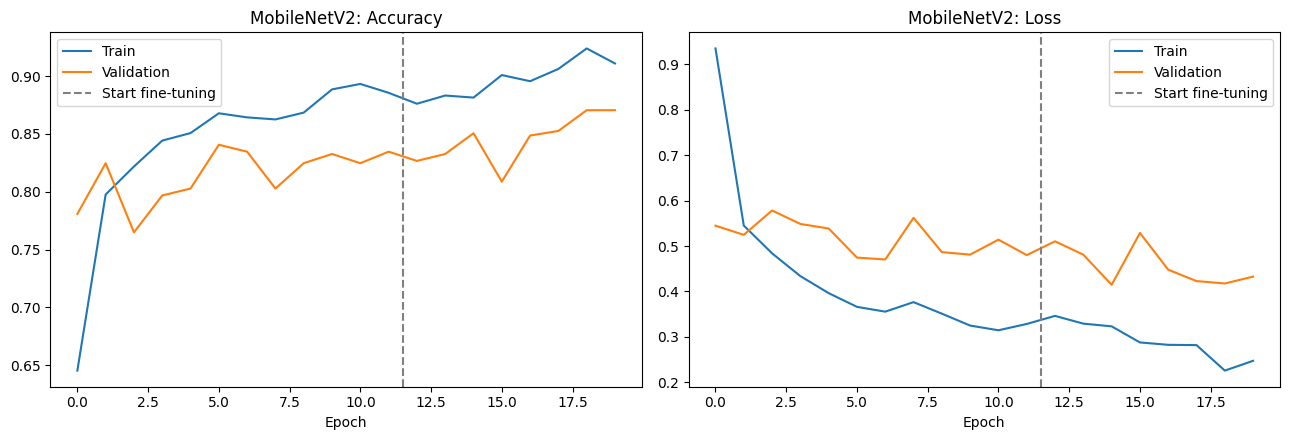

MobileNetV2 -> val acc: 0.8506 | test acc: 0.8333


In [7]:
m1 = train_transfer("MobileNetV2")

In [9]:
# 1) Patch src/models.py
p = "/content/project/src/models.py"
s = open(p).read()
s = s.replace('input_shape=(*IMG_SIZE, 3), name=f"{name.lower()}_base")',
              'input_shape=(*IMG_SIZE, 3))')
s = s.replace('base = next(l for l in model.layers if l.name.endswith("_base"))',
              'base = next(l for l in model.layers if isinstance(l, keras.Model))')
open(p, "w").write(s)

# 2) Reload the module so the notebook uses the fixed version
import importlib, src.models
importlib.reload(src.models)
from src.models import build_transfer_model, unfreeze_top_layers

!grep -n "isinstance(l, keras.Model)\|input_shape=(\*IMG_SIZE, 3))" /content/project/src/models.py

68:                           input_shape=(*IMG_SIZE, 3))
82:    base = next(l for l in model.layers if isinstance(l, keras.Model))


5: Train EfficientNetB0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

===== EfficientNetB0: phase 1 (frozen backbone) =====
Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 80s 971ms/step - accuracy: 0.6838 - loss: 0.8087 - val_accuracy: 0.6673 - val_loss: 0.8128 - learning_rate: 0.0010
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 440ms/step - accuracy: 0.8260 - loss: 0.4880 - val_accuracy: 0.7689 - val_loss: 0.5859 - learning_rate: 0.0010
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 401ms/step - accuracy: 0.8372 - loss: 0.4520 - val_accuracy: 0.7251 - val_loss: 0.7146 - learning_rate: 0.0010
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 438ms/step - accuracy: 0.8507 - loss: 0.4102 - val_accuracy: 0.8108 - val_loss: 0.5246 - learning_rate: 0.0010
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 405ms/step - accuracy: 0.8590 - loss: 0.3878 - val_accuracy: 0.7888 - val_loss: 0.5684 - learning_rate: 0.0010
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.8603 - loss: 0.3846
Epoch 6: ReduceLROnPlateau reducing learnin

53/53 ━━━━━━━━━━━━━━━━━━━━ 78s 919ms/step - accuracy: 0.9062 - loss: 0.2853 - val_accuracy: 0.8247 - val_loss: 0.4950
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 402ms/step - accuracy: 0.8909 - loss: 0.2807 - val_accuracy: 0.8247 - val_loss: 0.4991
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 437ms/step - accuracy: 0.8903 - loss: 0.2743 - val_accuracy: 0.8287 - val_loss: 0.5105
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 402ms/step - accuracy: 0.9086 - loss: 0.2731 - val_accuracy: 0.8167 - val_loss: 0.5364
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.9106 - loss: 0.2591

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 453ms/step - accuracy: 0.9044 - loss: 0.2705 - val_accuracy: 0.8327 - val_loss: 0.4735
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 380ms/step - accuracy: 0.9070 - loss: 0.2619

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 447ms/step - accuracy: 0.9068 - loss: 0.2690 - val_accuracy: 0.8307 - val_loss: 0.4669
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 403ms/step - accuracy: 0.9086 - loss: 0.2512 - val_accuracy: 0.8347 - val_loss: 0.4800
Epoch 8/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step - accuracy: 0.9083 - loss: 0.2585

53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 418ms/step - accuracy: 0.9062 - loss: 0.2584 - val_accuracy: 0.8426 - val_loss: 0.4479
Epoch 9/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 411ms/step - accuracy: 0.9180 - loss: 0.2396 - val_accuracy: 0.8267 - val_loss: 0.4891
Epoch 10/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 402ms/step - accuracy: 0.9127 - loss: 0.2463 - val_accuracy: 0.8367 - val_loss: 0.4656
Epoch 11/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.9067 - loss: 0.2499

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 446ms/step - accuracy: 0.9080 - loss: 0.2539 - val_accuracy: 0.8426 - val_loss: 0.4448
Epoch 12/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.9096 - loss: 0.2336

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 454ms/step - accuracy: 0.9109 - loss: 0.2443 - val_accuracy: 0.8466 - val_loss: 0.4295
Epoch 13/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 404ms/step - accuracy: 0.9268 - loss: 0.2178 - val_accuracy: 0.8386 - val_loss: 0.4529
Epoch 14/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.9176 - loss: 0.2351

53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 446ms/step - accuracy: 0.9150 - loss: 0.2396 - val_accuracy: 0.8526 - val_loss: 0.4200
Epoch 15/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 22s 405ms/step - accuracy: 0.9209 - loss: 0.2296 - val_accuracy: 0.8586 - val_loss: 0.4217
Restoring model weights from the end of the best epoch: 14.


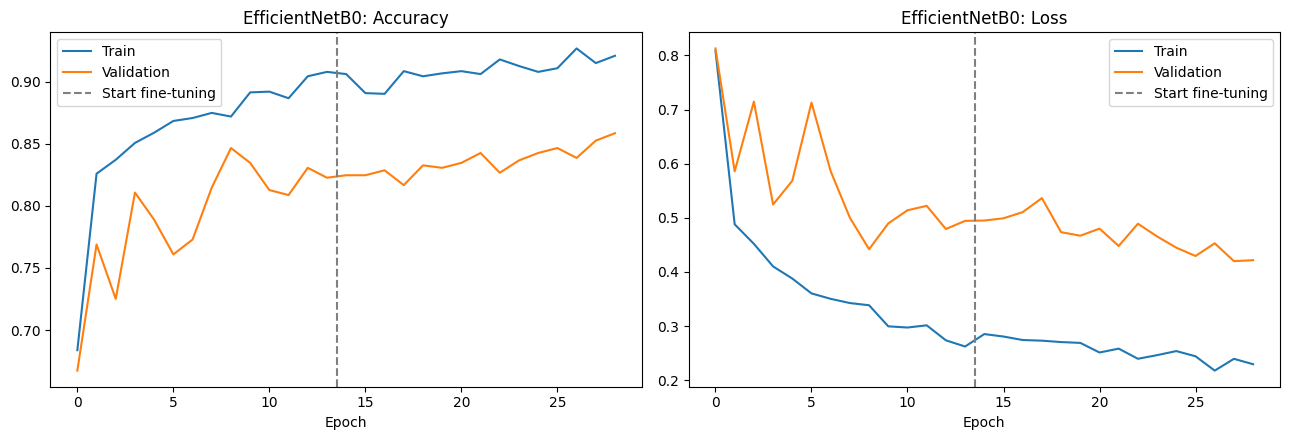

EfficientNetB0 -> val acc: 0.8526 | test acc: 0.8211


In [10]:
m2 = train_transfer("EfficientNetB0")

6: Train ResNet50

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

===== ResNet50: phase 1 (frozen backbone) =====
Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 55s 701ms/step - accuracy: 0.6307 - loss: 1.0427 - val_accuracy: 0.7590 - val_loss: 0.5735 - learning_rate: 0.0010
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 421ms/step - accuracy: 0.7994 - loss: 0.5389 - val_accuracy: 0.8486 - val_loss: 0.4232 - learning_rate: 0.0010
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 25s 444ms/step - accuracy: 0.8177 - loss: 0.5039 - val_accuracy: 0.8506 - val_loss: 0.3902 - learning_rate: 0.0010
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 433ms/step - accuracy: 0.8478 - loss: 0.4168 - val_accuracy: 0.7709 - val_loss: 0.6137 - learning_rate: 0.0010
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 417ms/step - accuracy: 0.8478 - loss: 0.4044 - val_accuracy: 0.8825 - val_loss: 0.3385 - learning_rate: 0.0010
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 25s 455ms/step - accuracy: 0.8796 - loss: 0.3430 - val_accuracy: 0.8526 - val_loss: 0.4141 - lear

53/53 ━━━━━━━━━━━━━━━━━━━━ 58s 707ms/step - accuracy: 0.9032 - loss: 0.2609 - val_accuracy: 0.8944 - val_loss: 0.3754
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.9171 - loss: 0.2337

53/53 ━━━━━━━━━━━━━━━━━━━━ 26s 464ms/step - accuracy: 0.9192 - loss: 0.2346 - val_accuracy: 0.9163 - val_loss: 0.2947
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 24s 449ms/step - accuracy: 0.9268 - loss: 0.2101 - val_accuracy: 0.8984 - val_loss: 0.3530
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 426ms/step - accuracy: 0.9257 - loss: 0.2008 - val_accuracy: 0.9143 - val_loss: 0.3070
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 25s 454ms/step - accuracy: 0.9339 - loss: 0.1915 - val_accuracy: 0.9004 - val_loss: 0.3466
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 425ms/step - accuracy: 0.9487 - loss: 0.1495 - val_accuracy: 0.9183 - val_loss: 0.3323
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 427ms/step - accuracy: 0.9499 - loss: 0.1452 - val_accuracy: 0.9223 - val_loss: 0.3138
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.


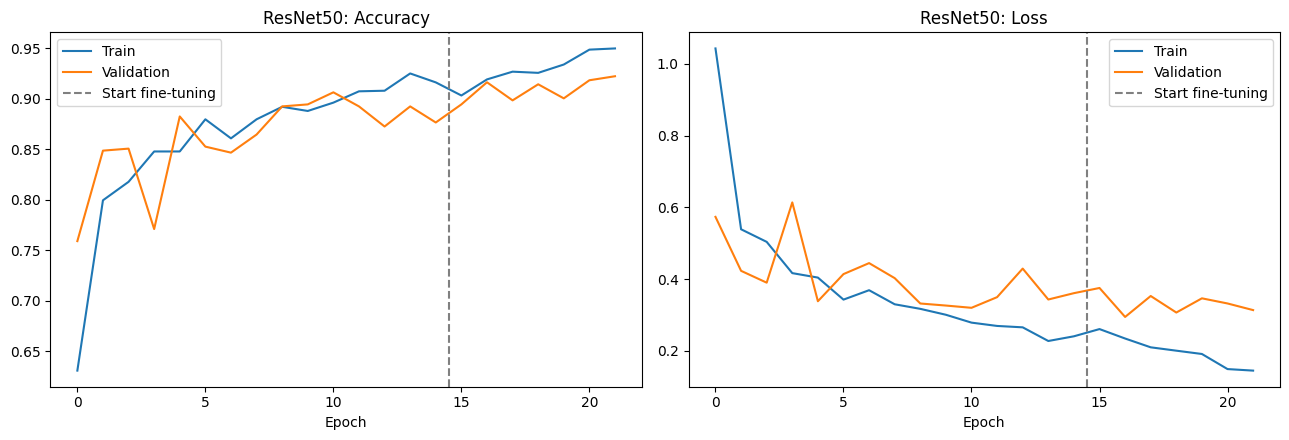

ResNet50 -> val acc: 0.9163 | test acc: 0.9106


In [11]:
m3 = train_transfer("ResNet50")

7: back up the results to Drive

In [12]:
!mkdir -p "{GDRIVE}/models" "{GDRIVE}/figures"
!cp /content/project/models/* "{GDRIVE}/models/"
!cp /content/project/reports/figures/* "{GDRIVE}/figures/"

8: Summary of results

In [15]:
summary = pd.DataFrame(results).T.round(4)
display(summary)
summary.to_csv(MODELS_DIR / "transfer_results.csv")

,val_loss,val_acc,test_loss,test_acc
MobileNetV2,0.4145,0.8506,0.4550,0.8333
EfficientNetB0,0.4200,0.8526,0.5166,0.8211
ResNet50,0.2947,0.9163,0.3403,0.9106


Model	                    



                             Val acc	           Test acc

Custom CNN

                              69.7%	               66.3%

MobileNetV2



                              85.1%	               83.3%

EfficientNetB0



	                          85.3%	               82.1%

ResNet50



	                          91.6%	               91.1%




## Transfer Learning Summary
- Backbones (ImageNet weights): MobileNetV2, EfficientNetB0, ResNet50
- Head: GlobalAveragePooling -> Dropout(0.3) -> Dense(256) -> Dropout(0.3) -> softmax(4)
- Phase 1: frozen backbone, Adam 1e-3, EarlyStopping; Phase 2: unfreeze top 40 layers (BatchNorm kept frozen), Adam 1e-5
- Best validation / test accuracy per model:ResNet50
- Observations: Best Model is ResNet50